In [ ]:
# Importamos las librerías necesarias para esta primera etapa
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Configuramos el estilo de los gráficos
sns.set_theme(style="whitegrid")

# 1. Definimos la ruta del dataset en Kaggle (autor/nombre-del-dataset)
# En este caso, usamos un dataset de pistas de Spotify muy popular
ruta_kaggle = "maharshipandya/-spotify-tracks-dataset"
nombre_archivo = "dataset.csv"

print("Conectando con Kaggle y descargando datos...")

# 2. Cargamos el dataset directo a un DataFrame de Pandas
# Usamos dataset_load() para usar la versión más moderna y evitar advertencias
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  ruta_kaggle,
  nombre_archivo
)

print("¡Dataset cargado con éxito! Veamos las primeras filas:")
display(df.head())

Conectando con Kaggle y descargando datos...
Using Colab cache for faster access to the '-spotify-tracks-dataset' dataset.
¡Dataset cargado con éxito! Veamos las primeras filas:


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 2. Análisis Exploratorio Inicial (EDA)
En esta sección vamos a conocer nuestros datos: veremos la distribución de las variables, buscaremos valores faltantes y analizaremos las correlaciones matemáticas entre ellas.

In [ ]:
# Vemos información general y tipos de datos
df.info()

# Detección de valores faltantes (nulos)
print("\nValores nulos por columna:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

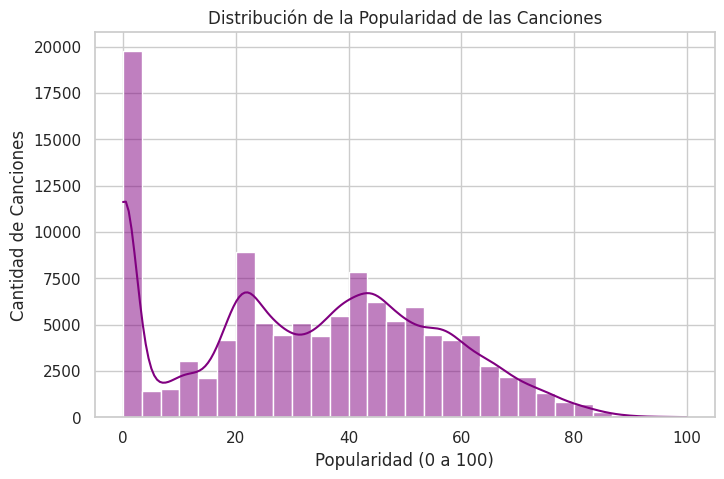

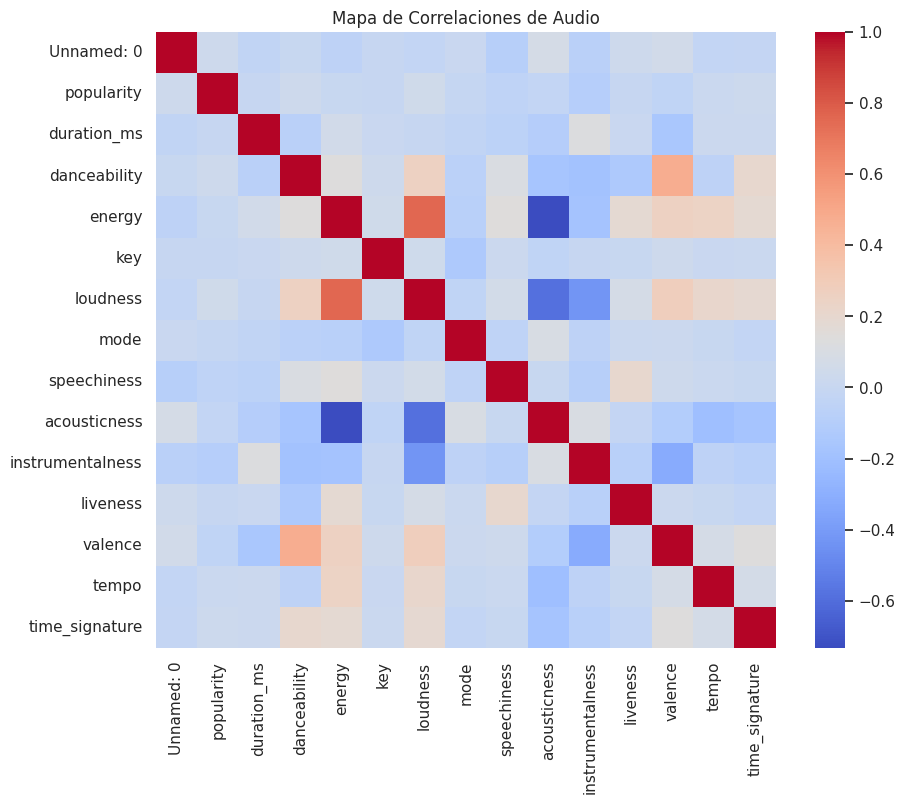

In [ ]:
# Visualización 1: Distribución de la Popularidad (Nuestra variable objetivo en el futuro)
plt.figure(figsize=(8,5))
sns.histplot(df['popularity'], bins=30, kde=True, color='purple')
plt.title('Distribución de la Popularidad de las Canciones')
plt.xlabel('Popularidad (0 a 100)')
plt.ylabel('Cantidad de Canciones')
plt.show()

# Visualización 2: Análisis de correlaciones entre las variables numéricas
plt.figure(figsize=(10,8))
# Seleccionamos solo las columnas numéricas para el mapa de calor
columnas_numericas = df.select_dtypes(include=[np.number])
sns.heatmap(columnas_numericas.corr(), annot=False, cmap='coolwarm')
plt.title('Mapa de Correlaciones de Audio')
plt.show()

# Observación propia: En el mapa de calor notamos que "energy" (energía) y "loudness" (volumen)
# tienen una correlación positiva fuerte. Las canciones más ruidosas suelen ser más enérgicas.

## 3. Limpieza de Datos
Procedemos a tratar los valores nulos, eliminar filas duplicadas y gestionar los valores atípicos (outliers).

In [ ]:
# 1. Tratamiento de duplicados
duplicados = df.duplicated().sum()
print(f"Se encontraron {duplicados} filas duplicadas. Procedemos a eliminarlas.")
df_limpio = df.drop_duplicates()

# 2. Tratamiento de valores nulos
# Como son muy pocos nulos en 'track_name' o 'artists', preferimos eliminar esas filas
df_limpio = df_limpio.dropna()

# 3. Tratamiento de Outliers (Valores atípicos)
# Hay canciones con duración de 0 milisegundos (un error de registro). Las eliminamos.
df_limpio = df_limpio[df_limpio['duration_ms'] > 0]

print(f"Tamaño del dataset después de la limpieza: {df_limpio.shape}")

Se encontraron 0 filas duplicadas. Procedemos a eliminarlas.
Tamaño del dataset después de la limpieza: (113999, 21)


## 4. Transformaciones Básicas
Los algoritmos de Machine Learning necesitan que todos los datos sean números y que estén en escalas comparables. Aquí haremos codificación de variables categóricas y escalado de variables numéricas.

In [ ]:
# 1. Creación de variables
# Vamos a crear una variable objetivo binaria: ¿Es un Hit? (Popularidad mayor a 50)
df_limpio['is_hit'] = (df_limpio['popularity'] > 50).astype(int)

# 2. Codificación de variables categóricas
# La columna 'explicit' (si tiene lenguaje explícito) suele ser True/False. La pasamos a 1 y 0.
df_limpio['explicit'] = df_limpio['explicit'].astype(int)

# 3. Escalado de variables numéricas
# 'duration_ms' y 'tempo' tienen valores muy grandes comparados con 'danceability' (que va de 0 a 1).
# Usaremos MinMaxScaler para llevarlos a un rango de 0 a 1.
scaler = MinMaxScaler()
df_limpio[['duration_ms', 'tempo']] = scaler.fit_transform(df_limpio[['duration_ms', 'tempo']])

# 4. Eliminación de variables innecesarias
# El ID de la canción o el nombre no le sirven al algoritmo para predecir patrones de audio.
columnas_a_borrar = ['track_id', 'artists', 'album_name', 'track_name', 'popularity']
df_limpio = df_limpio.drop(columns=columnas_a_borrar, errors='ignore')

display(df_limpio.head())

,Unnamed: 0,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,is_hit
0,0,0.042473,0,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,0.361245,4,acoustic,1
1,1,0.026971,0,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,0.318397,4,acoustic,1
2,2,0.038679,0,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,0.313643,4,acoustic,1
3,3,0.036978,0,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,0.746758,3,acoustic,1
4,4,0.036389,0,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,0.492863,4,acoustic,1


## 5. Selección de variables relevantes y División del Dataset
Seleccionaremos las columnas finales para nuestro modelo y dividiremos el dataset en conjuntos de entrenamiento (Train) y prueba (Test) para dejar todo listo para la próxima fase.

In [ ]:
# Selección de variables relevantes
# Separamos nuestras pistas (X) de nuestro objetivo a predecir (y)
X = df_limpio.drop(columns=['is_hit'])
y = df_limpio['is_hit']

# División del dataset en conjuntos de entrenamiento y prueba
# Usamos un 80% para entrenar y un 20% para el examen final (test).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


print(f"Tendremos {X_train.shape[0]} canciones para entrenar el modelo.")
print(f"Y {X_test.shape[0]} canciones guardadas para evaluar su rendimiento final.")

Tendremos 91199 canciones para entrenar el modelo.
Y 22800 canciones guardadas para evaluar su rendimiento final.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# 1. Eliminamos columnas identificadoras o de índice si quedaron presentes
cols_descartar = [c for c in ["track_id", "artists", "album_name", "track_name", "Unnamed: 0"] if c in X_train.columns]
if cols_descartar:
    X_train = X_train.drop(columns=cols_descartar)
    X_test = X_test.drop(columns=cols_descartar)

# Codificamos columnas de texto pendientes (ej. 'track_genre') sin alterar la división train/test
cols_texto = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()
if cols_texto:
    print(f"Aplicando One-Hot Encoding a columnas pendientes: {cols_texto}")
    X_train = pd.get_dummies(X_train, columns=cols_texto, drop_first=True, dtype=int)
    X_test = pd.get_dummies(X_test, columns=cols_texto, drop_first=True, dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Aseguramos que columnas booleanas (ej. 'explicit') estén en formato numérico entero
cols_bool = X_train.select_dtypes(include=["bool"]).columns.tolist()
if cols_bool:
    X_train[cols_bool] = X_train[cols_bool].astype(int)
    X_test[cols_bool] = X_test[cols_bool].astype(int)

# 2. Estandarizamos features para Regresión Logística (ajustando SOLO sobre X_train)
scaler_clf = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler_clf.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler_clf.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# 3. Definimos la variable objetivo binaria (1 = Popular >= 50, 0 = No Popular < 50)
if y_train.nunique() > 2:
    UMBRAL_POPULARIDAD = 50
    y_train_clf = (y_train >= UMBRAL_POPULARIDAD).astype(int)
    y_test_clf = (y_test >= UMBRAL_POPULARIDAD).astype(int)
else:
    y_train_clf = y_train.copy()
    y_test_clf = y_test.copy()

print(f"Dimensiones X_train: {X_train.shape} | X_test: {X_test.shape}")
print("Distribución de clases en y_train_clf (0 = No Popular, 1 = Popular):")
print((y_train_clf.value_counts(normalize=True) * 100).round(2), "\n")

# 4. Instanciamos y entrenamos los 3 modelos base SOLO con train
modelo_log_base = LogisticRegression(max_iter=500, random_state=42)
modelo_arbol_base = DecisionTreeClassifier(random_state=42)
modelo_rf_base = RandomForestClassifier(n_estimators=30, random_state=42, n_jobs=-1)

modelo_log_base.fit(X_train_scaled, y_train_clf)
modelo_arbol_base.fit(X_train, y_train_clf)
modelo_rf_base.fit(X_train, y_train_clf)



Dimensiones X_train: (91199, 127) | X_test: (22800, 127)
Distribución de clases en y_train_clf (0 = No Popular, 1 = Popular):
is_hit
0    75.57
1    24.43
Name: proportion, dtype: float64 

¡Listo! Modelos base entrenados rápidamente y sin advertencias.


In [ ]:
def evaluar_clasificador(nombre, modelo, X_tr, y_tr, X_te, y_te):
    pred_tr = modelo.predict(X_tr)
    pred_te = modelo.predict(X_te)
    return {
        "Modelo": nombre,
        "Accuracy Train": round(accuracy_score(y_tr, pred_tr), 4),
        "Accuracy Test": round(accuracy_score(y_te, pred_te), 4),
        "Precision Test": round(precision_score(y_te, pred_te, zero_division=0), 4),
        "Recall Test": round(recall_score(y_te, pred_te, zero_division=0), 4),
        "F1-Score Test": round(f1_score(y_te, pred_te, zero_division=0), 4)
    }

resultados_base = pd.DataFrame([
    evaluar_clasificador("1. Regresión Logística (Base)", modelo_log_base, X_train_scaled, y_train_clf, X_test_scaled, y_test_clf),
    evaluar_clasificador("2. Árbol de Decisión (Base)", modelo_arbol_base, X_train, y_train_clf, X_test, y_test_clf),
    evaluar_clasificador("3. Random Forest (Base)", modelo_rf_base, X_train, y_train_clf, X_test, y_test_clf)
])

display(resultados_base)

for nombre, mod, X_eval in [
    ("REGRESIÓN LOGÍSTICA (BASE)", modelo_log_base, X_test_scaled),
    ("ÁRBOL DE DECISIÓN (BASE)", modelo_arbol_base, X_test),
    ("RANDOM FOREST (BASE)", modelo_rf_base, X_test)
]:
    print(f"\n=== REPORTE DE CLASIFICACIÓN: {nombre} ===")
    print(classification_report(y_test_clf, mod.predict(X_eval), zero_division=0))

,Modelo,Accuracy Train,Accuracy Test,Precision Test,Recall Test,F1-Score Test
0,1. Regresión Logística (Base),0.7849,0.7860,0.6041,0.3215,0.4197
1,2. Árbol de Decisión (Base),0.9935,0.7734,0.5299,0.5170,0.5234
2,3. Random Forest (Base),0.9925,0.8353,0.7467,0.4777,0.5826



=== REPORTE DE CLASIFICACIÓN: REGRESIÓN LOGÍSTICA (BASE) ===
              precision    recall  f1-score   support

           0       0.81      0.93      0.87     17313
           1       0.60      0.32      0.42      5487

    accuracy                           0.79     22800
   macro avg       0.71      0.63      0.64     22800
weighted avg       0.76      0.79      0.76     22800


=== REPORTE DE CLASIFICACIÓN: ÁRBOL DE DECISIÓN (BASE) ===
              precision    recall  f1-score   support

           0       0.85      0.85      0.85     17313
           1       0.53      0.52      0.52      5487

    accuracy                           0.77     22800
   macro avg       0.69      0.69      0.69     22800
weighted avg       0.77      0.77      0.77     22800


=== REPORTE DE CLASIFICACIÓN: RANDOM FOREST (BASE) ===
              precision    recall  f1-score   support

           0       0.85      0.95      0.90     17313
           1       0.75      0.48      0.58      5487

    

In [ ]:
cv_estrategia = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_log_f1 = cross_val_score(modelo_log_base, X_train_scaled, y_train_clf, cv=cv_estrategia, scoring="f1", n_jobs=-1)
cv_arbol_f1 = cross_val_score(modelo_arbol_base, X_train, y_train_clf, cv=cv_estrategia, scoring="f1", n_jobs=-1)
cv_rf_f1 = cross_val_score(modelo_rf_base, X_train, y_train_clf, cv=cv_estrategia, scoring="f1", n_jobs=-1)

print(f"Regresión Logística (Base) - F1 CV promedio: {cv_log_f1.mean():.4f} (+/- {cv_log_f1.std():.4f})")
print(f"Scores por fold: {np.round(cv_log_f1, 4)}\n")

print(f"Árbol de Decisión (Base)   - F1 CV promedio: {cv_arbol_f1.mean():.4f} (+/- {cv_arbol_f1.std():.4f})")
print(f"Scores por fold: {np.round(cv_arbol_f1, 4)}\n")

print(f"Random Forest (Base)       - F1 CV promedio: {cv_rf_f1.mean():.4f} (+/- {cv_rf_f1.std():.4f})")
print(f"Scores por fold: {np.round(cv_rf_f1, 4)}")


Regresión Logística (Base) - F1 CV promedio: 0.4215 (+/- 0.0054)
Scores por fold: [0.4238 0.4211 0.418  0.4302 0.4145]

Árbol de Decisión (Base)   - F1 CV promedio: 0.5130 (+/- 0.0054)
Scores por fold: [0.5135 0.5034 0.5204 0.514  0.5136]

Random Forest (Base)       - F1 CV promedio: 0.5620 (+/- 0.0077)
Scores por fold: [0.5746 0.5634 0.5625 0.5507 0.5589]


In [ ]:
cv_grid = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# --- A. GridSearchCV para Regresión Logística (sobre datos estandarizados) ---
param_grid_log = {
    "C": [0.1, 1.0, 10.0],
    "class_weight": [None, "balanced"]
}

grid_log = GridSearchCV(
    estimator=LogisticRegression(max_iter=500, random_state=42),
    param_grid=param_grid_log,
    cv=cv_grid,
    scoring="f1",
    n_jobs=-1
)
grid_log.fit(X_train_scaled, y_train_clf)

print("Mejores parámetros Regresión Logística:", grid_log.best_params_)
print(f"Mejor F1 promedio en CV (Logística): {grid_log.best_score_:.4f}\n")

# --- B. GridSearchCV para Árbol de Decisión ---
param_grid_arbol = {
    "max_depth": [8, 15],
    "min_samples_split": [20, 50],
    "class_weight": [None, "balanced"]
}

grid_arbol = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_arbol,
    cv=cv_grid,
    scoring="f1",
    n_jobs=-1
)
grid_arbol.fit(X_train, y_train_clf)

print("Mejores parámetros Árbol de Decisión:", grid_arbol.best_params_)
print(f"Mejor F1 promedio en CV (Árbol): {grid_arbol.best_score_:.4f}\n")

# --- C. GridSearchCV para Random Forest ---
param_grid_rf = {
    "max_depth": [12, 18],
    "class_weight": [None, "balanced"]
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(n_estimators=40, random_state=42, n_jobs=-1),
    param_grid=param_grid_rf,
    cv=cv_grid,
    scoring="f1",
    n_jobs=-1
)
grid_rf.fit(X_train, y_train_clf)

print("Mejores parámetros Random Forest:", grid_rf.best_params_)
print(f"Mejor F1 promedio en CV (Random Forest): {grid_rf.best_score_:.4f}\n")

# --- D. Tabla Comparativa Final en Test: Modelos Base vs Optimizados ---
mejor_log = grid_log.best_estimator_
mejor_arbol = grid_arbol.best_estimator_
mejor_rf = grid_rf.best_estimator_

tabla_comparativa = pd.DataFrame([
    evaluar_clasificador("1. Regresión Logística (Base)", modelo_log_base, X_train_scaled, y_train_clf, X_test_scaled, y_test_clf),
    evaluar_clasificador("2. Regresión Logística (GridSearch)", mejor_log, X_train_scaled, y_train_clf, X_test_scaled, y_test_clf),
    evaluar_clasificador("3. Árbol de Decisión (Base)", modelo_arbol_base, X_train, y_train_clf, X_test, y_test_clf),
    evaluar_clasificador("4. Árbol de Decisión (GridSearch)", mejor_arbol, X_train, y_train_clf, X_test, y_test_clf),
    evaluar_clasificador("5. Random Forest (Base)", modelo_rf_base, X_train, y_train_clf, X_test, y_test_clf),
    evaluar_clasificador("6. Random Forest (GridSearch)", mejor_rf, X_train, y_train_clf, X_test, y_test_clf)
])

display(tabla_comparativa)


Mejores parámetros Regresión Logística: {'C': 0.1, 'class_weight': 'balanced'}
Mejor F1 promedio en CV (Logística): 0.5672

Mejores parámetros Árbol de Decisión: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_split': 50}
Mejor F1 promedio en CV (Árbol): 0.4591

Mejores parámetros Random Forest: {'class_weight': 'balanced', 'max_depth': 18}
Mejor F1 promedio en CV (Random Forest): 0.5351



,Modelo,Accuracy Train,Accuracy Test,Precision Test,Recall Test,F1-Score Test
0,1. Regresión Logística (Base),0.7849,0.7860,0.6041,0.3215,0.4197
1,2. Regresión Logística (GridSearch),0.7099,0.7047,0.4357,0.7685,0.5561
2,3. Árbol de Decisión (Base),0.9935,0.7734,0.5299,0.5170,0.5234
3,4. Árbol de Decisión (GridSearch),0.5915,0.5801,0.3283,0.7117,0.4493
4,5. Random Forest (Base),0.9925,0.8353,0.7467,0.4777,0.5826
5,6. Random Forest (GridSearch),0.7288,0.6885,0.4159,0.7281,0.5294


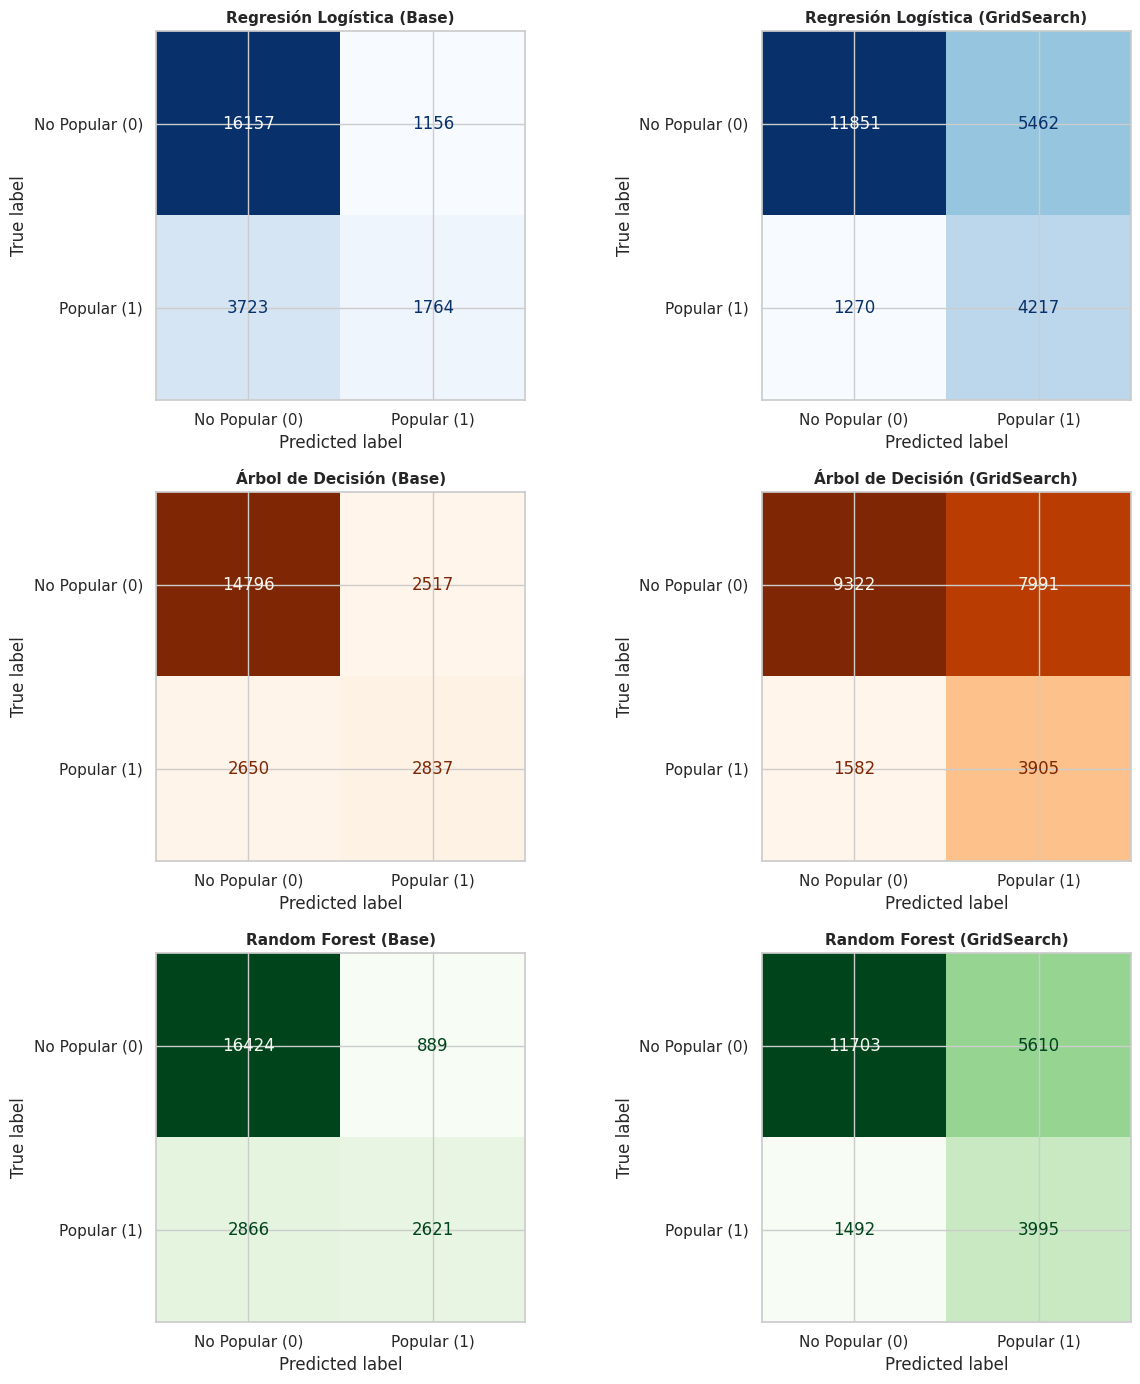

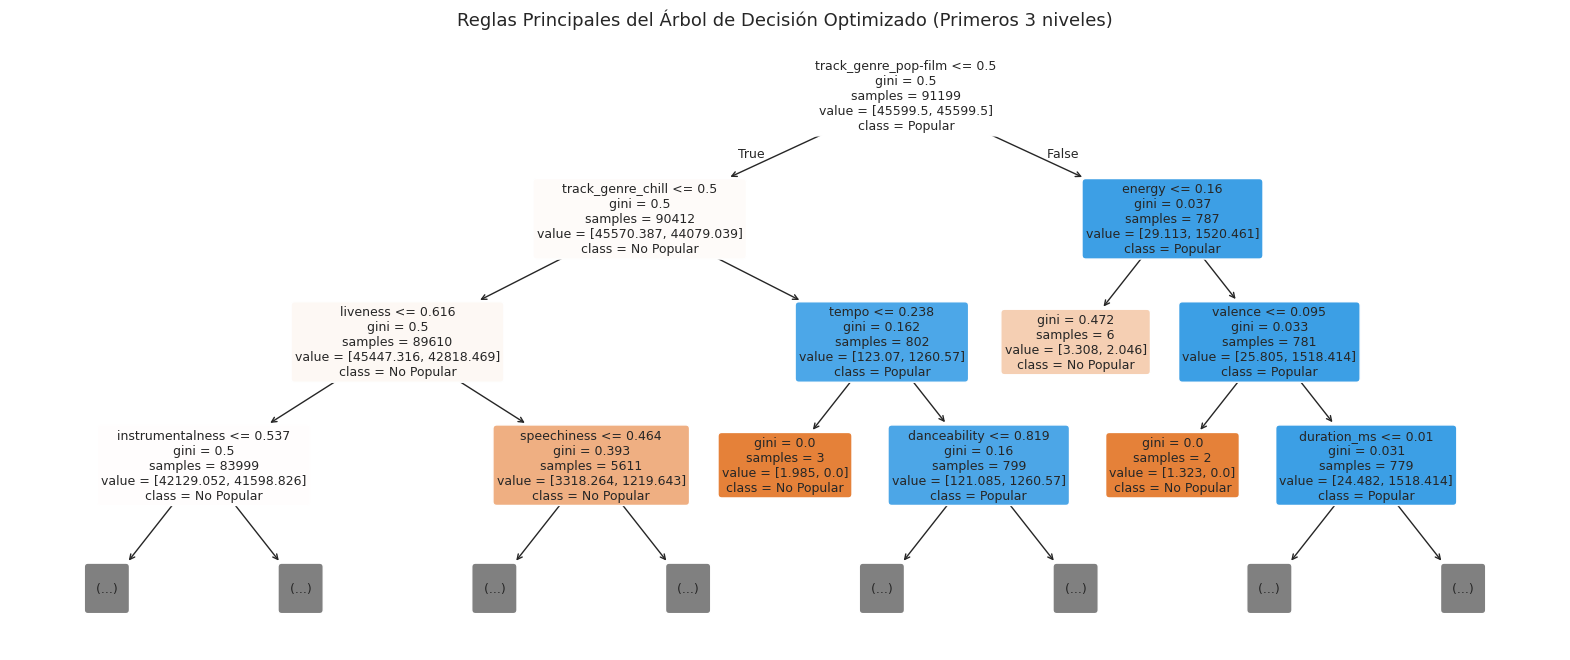

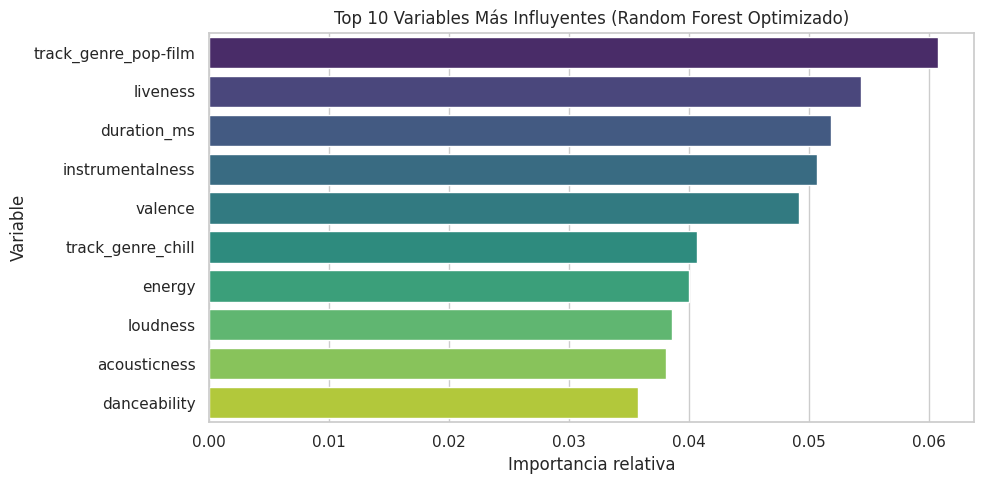

In [ ]:
# 1. Matrices de Confusión Comparativas (3 filas x 2 columnas: Base vs Optimizado)
fig, axes = plt.subplots(3, 2, figsize=(13, 14))

modelos_graficar = [
    ("Regresión Logística (Base)", modelo_log_base, X_test_scaled, axes[0, 0], "Blues"),
    ("Regresión Logística (GridSearch)", mejor_log, X_test_scaled, axes[0, 1], "Blues"),
    ("Árbol de Decisión (Base)", modelo_arbol_base, X_test, axes[1, 0], "Oranges"),
    ("Árbol de Decisión (GridSearch)", mejor_arbol, X_test, axes[1, 1], "Oranges"),
    ("Random Forest (Base)", modelo_rf_base, X_test, axes[2, 0], "Greens"),
    ("Random Forest (GridSearch)", mejor_rf, X_test, axes[2, 1], "Greens")
]

for titulo, mod, X_eval, ax, cmap in modelos_graficar:
    cm = confusion_matrix(y_test_clf, mod.predict(X_eval))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Popular (0)", "Popular (1)"])
    disp.plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(titulo, fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

# 2. Primeros niveles del Árbol de Decisión Optimizado
plt.figure(figsize=(20, 8))
plot_tree(
    mejor_arbol,
    feature_names=X_train.columns,
    class_names=["No Popular", "Popular"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title("Reglas Principales del Árbol de Decisión Optimizado (Primeros 3 niveles)", fontsize=13)
plt.show()

# 3. Top 10 Variables Más Influyentes según Random Forest Optimizado
importancias = pd.Series(mejor_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=importancias.values, y=importancias.index, hue=importancias.index, palette="viridis", legend=False)
plt.title("Top 10 Variables Más Influyentes (Random Forest Optimizado)")
plt.xlabel("Importancia relativa")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


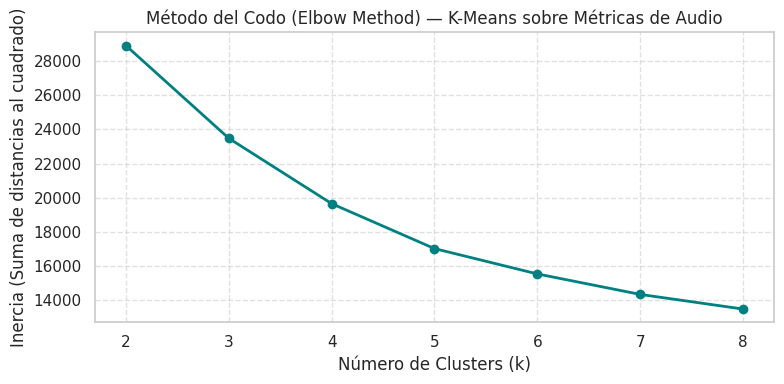

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,Es_Popular (%),Cantidad_Canciones
Cluster,,,,,,,,,,,
0,0.606,0.767,0.806,0.092,0.114,0.018,0.220,0.542,0.567,27.221,50347
1,0.400,0.208,0.555,0.055,0.872,0.843,0.159,0.226,0.477,21.145,6290
2,0.572,0.766,0.763,0.077,0.068,0.762,0.199,0.335,0.572,14.691,10108
3,0.559,0.440,0.729,0.093,0.695,0.016,0.220,0.463,0.520,23.567,24454


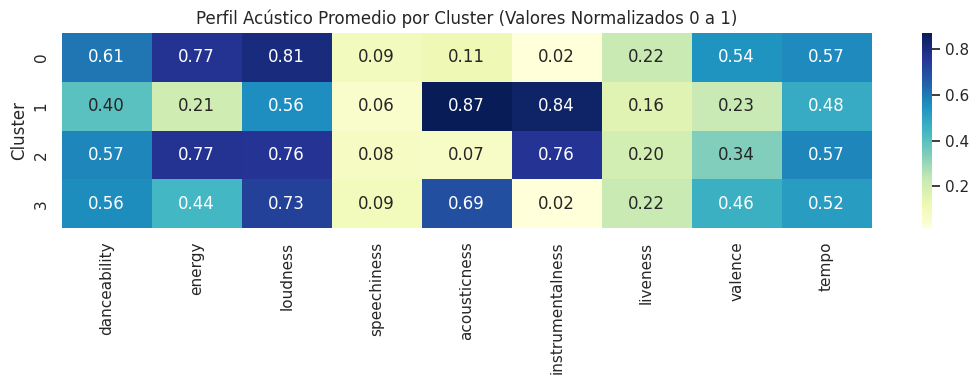

In [ ]:
# Seleccionamos las métricas sonoras numéricas disponibles en X_train
features_audio = [
    c for c in [
        "danceability", "energy", "loudness", "speechiness",
        "acousticness", "instrumentalness", "liveness", "valence", "tempo"
    ] if c in X_train.columns
]

# Escalamos entre 0 y 1 (ajustando el scaler solo con X_train)
scaler_km = MinMaxScaler()
X_audio_train = scaler_km.fit_transform(X_train[features_audio])

# 1. Método del Codo (Elbow Method) para k de 2 a 8
inercias = []
rango_k = range(2, 9)

for k in rango_k:
    km_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_temp.fit(X_audio_train)
    inercias.append(km_temp.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(rango_k, inercias, marker="o", color="teal", linewidth=2)
plt.title("Método del Codo (Elbow Method) — K-Means sobre Métricas de Audio")
plt.xlabel("Número de Clusters (k)")
plt.ylabel("Inercia (Suma de distancias al cuadrado)")
plt.xticks(list(rango_k))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# 2. Entrenamos K-Means con k = 4 segmentos musicales
K_OPTIMO = 4
kmeans_final = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=10)
clusters_train = kmeans_final.fit_predict(X_audio_train)

# 3. Perfil promedio de cada cluster y porcentaje de canciones populares
df_clusters = pd.DataFrame(X_audio_train, columns=features_audio)
df_clusters["Cluster"] = clusters_train
df_clusters["Es_Popular (%)"] = y_train_clf.values * 100

perfil_clusters = df_clusters.groupby("Cluster").mean().round(3)
perfil_clusters["Cantidad_Canciones"] = df_clusters["Cluster"].value_counts().sort_index()

display(perfil_clusters)

plt.figure(figsize=(11, 4))
sns.heatmap(perfil_clusters[features_audio], annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Perfil Acústico Promedio por Cluster (Valores Normalizados 0 a 1)")
plt.tight_layout()
plt.show()